# EDA 04 · Listening logs table

**Part I · Raw tables** · part of the 10-notebook EDA series in `workshops/w1/eda/` (index in `README.md`).

**Question.** What is the scale and shape of the daily listening counters, and how should outliers be handled?

**Data.** Listening logs. Only a one-million-row sample of `user_logs_v2` is read because the full file is about 32 GB.

**How to read it.** The counters have very long tails; the percentile tables justify clipping.

In [ ]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Paths resolve from the w1 folder, whether the notebook runs from workshops/w1 or workshops/w1/eda.
W1_DIR = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
DATA_DIR = W1_DIR.parent / "data"      # workshops/data: raw .csv.7z archives
PARQUET_DIR = DATA_DIR / "parquet"     # created once by notebook 01 (or by w1_data_preprocessing)

sns.set()
warnings.filterwarnings("ignore")

PCTS = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 98, 99, 99.5, 99.99, 99.999, 100]


def tabla_percentiles(serie):
    return pd.DataFrame(np.percentile(serie, PCTS), index=PCTS, columns=["valor"])

## 4. User logs

`user_logs_v2.parquet` is a huge file; a 1M-row subset is used for visualization.

In [49]:
# user_logs_v2.parquet is huge; a 1M-row sample is enough for visualisation.
user_logs = pl.read_parquet(PARQUET_DIR / "user_logs_v2.parquet", n_rows=1_000_000).to_pandas()
user_logs["date"] = pd.to_datetime(user_logs["date"].astype(str), format="%Y%m%d")

In [50]:
user_logs.head()

,msno,date,num_25,num_50,num_75,num_985,num_100,num_unq,total_secs
0,u9E91QDTvHLq6NXjEaWv8u4QIqhrHk72kE+w31Gnhdg=,2017-03-31,8,4,0,1,21,18,6309.273
1,nTeWW/eOZA/UHKdD5L7DEqKKFTjaAj3ALLPoAWsU8n0=,2017-03-30,2,2,1,0,9,11,2390.699
2,2UqkWXwZbIjs03dHLU9KHJNNEvEkZVzm69f3jCS+uLI=,2017-03-31,52,3,5,3,84,110,23203.337
3,ycwLc+m2O0a85jSLALtr941AaZt9ai8Qwlg9n0Nql5U=,2017-03-31,176,4,2,2,19,191,7100.454
4,EGcbTofOSOkMmQyN1NMLxHEXJ1yV3t/JdhGwQ9wXjnI=,2017-03-31,2,1,0,1,112,93,28401.558


Contains 9 columns, all numerical features. Since these are user logs, more than one entry per user is very common. Logs are divided by days.

In [51]:
user_logs.shape  # just 1 month of data; the initial log file is ~32 GB

(1000000, 9)

In [52]:
user_logs.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 9 columns):
 #   Column      Non-Null Count    Dtype         
---  ------      --------------    -----         
 0   msno        1000000 non-null  str           
 1   date        1000000 non-null  datetime64[us]
 2   num_25      1000000 non-null  int32         
 3   num_50      1000000 non-null  int32         
 4   num_75      1000000 non-null  int32         
 5   num_985     1000000 non-null  int32         
 6   num_100     1000000 non-null  int32         
 7   num_unq     1000000 non-null  int32         
 8   total_secs  1000000 non-null  float64       
dtypes: datetime64[us](1), float64(1), int32(6), str(1)
memory usage: 87.7 MB


Memory can be optimized.

In [53]:
user_logs.describe().apply(lambda s: s.apply(lambda x: format(x, "f")))

,date,num_25,num_50,num_75,num_985,num_100,num_unq,total_secs
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,f,6.195458,1.509556,0.943134,1.081309,30.304456,29.071834,7911.606792
min,f,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.023000
25%,f,0.000000,0.000000,0.000000,0.000000,7.000000,8.000000,1967.845750
50%,f,2.000000,1.000000,0.000000,0.000000,17.000000,19.000000,4598.790500
75%,f,7.000000,2.000000,1.000000,1.000000,37.000000,38.000000,9855.994000
max,f,2101.000000,558.000000,241.000000,957.000000,2120.000000,877.000000,515927.542000
std,nan,12.972856,3.953778,1.914086,3.587555,39.839431,32.037360,9641.563675


- `msno`: user id
- `date`: format %Y%m%d
- `num_25`: # of songs played less than 25% of the song length
- `num_50`: # of songs played between 25% to 50% of the song length
- `num_75`: # of songs played between 50% to 75% of the song length
- `num_985`: # of songs played between 75% to 98.5% of the song length
- `num_100`: # of songs played over 98.5% of the song length
- `num_unq`: # of unique songs played
- `total_secs`: total seconds played

For most users `num_25` and `num_100` are high while `num_50` and `num_75` are mostly low.

In [54]:
# percentiles because the maximum values of these features are unusually high
tabla_percentiles(user_logs["num_25"])

,valor
0.000,0.00000
10.000,0.00000
20.000,0.00000
30.000,1.00000
40.000,1.00000
50.000,2.00000
60.000,4.00000
70.000,5.00000
80.000,9.00000
90.000,16.00000


Clearly there are some outliers.

In [55]:
tabla_percentiles(user_logs["num_50"])

,valor
0.000,0.00000
10.000,0.00000
20.000,0.00000
30.000,0.00000
40.000,0.00000
50.000,1.00000
60.000,1.00000
70.000,1.00000
80.000,2.00000
90.000,4.00000


In [56]:
tabla_percentiles(user_logs["num_75"])

,valor
0.000,0.00000
10.000,0.00000
20.000,0.00000
30.000,0.00000
40.000,0.00000
50.000,0.00000
60.000,1.00000
70.000,1.00000
80.000,2.00000
90.000,3.00000


In [57]:
tabla_percentiles(user_logs["num_985"])

,valor
0.000,0.00000
10.000,0.00000
20.000,0.00000
30.000,0.00000
40.000,0.00000
50.000,0.00000
60.000,1.00000
70.000,1.00000
80.000,2.00000
90.000,3.00000


In [58]:
tabla_percentiles(user_logs["num_100"])

,valor
0.000,0.00000
10.000,2.00000
20.000,5.00000
30.000,8.00000
40.000,12.00000
50.000,17.00000
60.000,23.00000
70.000,31.00000
80.000,45.00000
90.000,76.00000


The conclusion from the dataframes above is that we need to set a threshold above some value because they look like outliers.

### Plots between

1. distribution of `num_25`
2. distribution of `num_50`
3. distribution of `num_75`
4. distribution of `num_985`
5. distribution of `num_100`

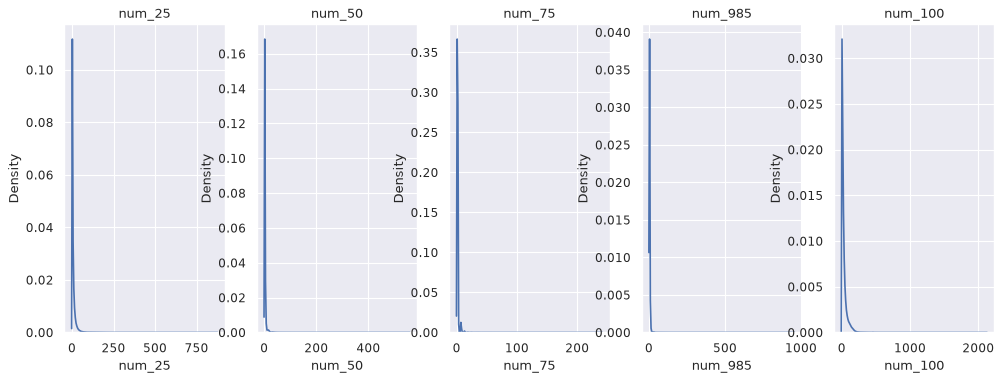

In [59]:
figure(num=None, figsize=(15, 5), dpi=80, facecolor="w", edgecolor="k")
plt.subplot(151)
sns.kdeplot(x=user_logs["num_25"][user_logs["num_25"] < 1000])
plt.title("num_25")
plt.xlabel("num_25")
plt.subplot(152)
sns.kdeplot(x=user_logs["num_50"])
plt.title("num_50")
plt.xlabel("num_50")
plt.subplot(153)
sns.kdeplot(x=user_logs["num_75"])
plt.title("num_75")
plt.xlabel("num_75")
plt.subplot(154)
sns.kdeplot(x=user_logs["num_985"])
plt.title("num_985")
plt.xlabel("num_985")
plt.subplot(155)
sns.kdeplot(x=user_logs["num_100"])
plt.title("num_100")
plt.xlabel("num_100")
plt.show()

The pattern shows a rise, a fall and then a rise again in all five plots. The most interesting observation is that in almost all five graphs there is a minimum in the middle, i.e. the value rises again at the end.

This pattern is very obvious and common: most people listen to some songs. There are very few people who listen to 50-75% of a song; people either listen to less than 25% or to 100% of it. This shows how much a user loved a song.

### Plot between counts and entries per user

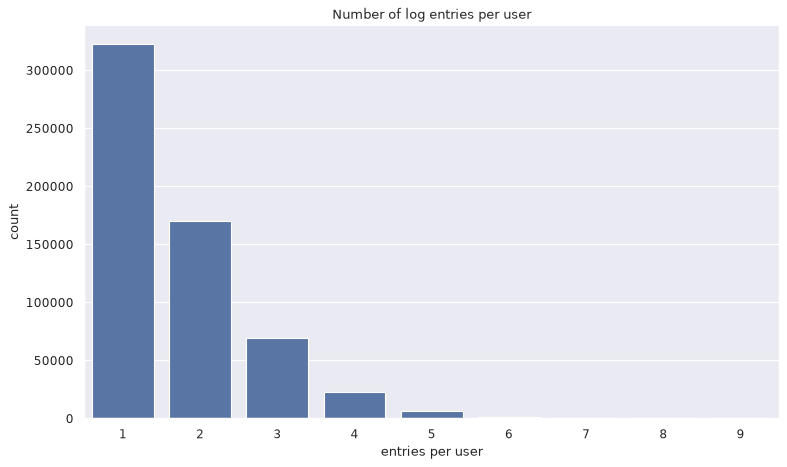

In [60]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=user_logs["msno"].value_counts().values)
plt.title("Number of log entries per user")
plt.xlabel("entries per user")
plt.ylabel("count")
plt.tight_layout()
plt.show()

It can be seen that either we have very little information about the user or we have a lot of it.

Listening to 1,200 songs in one day is not possible, so values above 1,200 can be considered outliers.

**User logs.**

- The `num_*` and `total_secs` variables have very long tails, so they must be clipped by percentile.
- Listening is bimodal: people skip the song before 25% or listen to it fully. This is a measure of affinity.
- The number of records per user is also bimodal: either very few or many.

---
**Previous:** `03_transactions.ipynb` · **Next:** `05_dates.ipynb`